### Key Design Clarifications Before Code Execution

Before running the blocks, note the **4 architectural decisions** made in the code below to ensure everything works smoothly with `sarvamai/sarvam-2b-v0.5`:

1. **Data Merging Across 4 Languages (Block 5 & 9):** The original code only loads and merges 2 CSV files (`input_lang` and `target_lang`) against `word_original` (`en`). Since we also need Hindi (`hi`) in `principal_lang_candidates`, the updated code loads `hi/clean.csv`, `input_lang/clean.csv`, and `target_lang/clean.csv` and merges all of them on `word_original` so every row has `"en"`, `"hi"`, `input_lang`, and `target_lang` columns.


2. **Intersection Filtering Rule (Block 11):** The original paper filters out rows where the latent token IDs overlap with the target token IDs (`intersection = set(out_token_id).intersection(set(latent_token_id))`) so shared substrings don't artificially inflate latent probabilities. In your 4-candidate setup, `target_lang` is itself in the candidate list (where intersection is 100%). The code below applies the disjoint check **only** when $c \neq \text{target\_lang}$, and **skips** the strict disjoint check between `hi` and Marathi (`mar`) if they share identical Devanagari root prefixes—otherwise, cognate overlap would drop most of your dataset. (You can toggle `strict_disjoint = False` in Block 11).


3. **Plotting 4 Subplots vs. `plot_ci_plus_heatmap` (Block 17):** In `utils.py`, `plot_ci_plus_heatmap` creates its own standalone `Figure` internally rather than accepting a subplot `ax`. To give you **Option A** cleanly without breaking `utils.py`, Block 17 provides both:


* A $2 \times 2$ unified Matplotlib grid using `plot_ci` (which accepts `ax`) with an entropy bar above each subplot.
* A loop calling the original `plot_ci_plus_heatmap` 4 times to save the exact paper-style PDFs for each candidate language.




4. **Sarvam-2B Architecture:** `sarvamai/sarvam-2b-v0.5` uses the `LlamaForCausalLM` architecture (`28` layers, `2048` hidden size) and a SentencePiece tokenizer (`▁` space prefix), so `LlamaHelper` and `llama.model.model.norm` work out of the box.

In [3]:
!nvidia-smi --query-gpu=index,memory.used,memory.free --format=csv

index, memory.used [MiB], memory.free [MiB]
0, 12959 MiB, 19541 MiB
1, 8481 MiB, 24019 MiB
2, 6469 MiB, 26031 MiB
3, 12827 MiB, 19673 MiB
4, 31319 MiB, 1181 MiB
5, 26125 MiB, 6375 MiB
6, 30647 MiB, 1853 MiB
7, 32193 MiB, 307 MiB


#### Block 1: Autoreload & Imports

Loads standard libraries and `LlamaHelper` / `utils` from the repository.

In [4]:
%load_ext autoreload
%autoreload 2

import pandas as pd
import sys
import os
sys.path.append('/raid/home/dgx1405/btp1-2026/llm-latent-language')
from dataclasses import dataclass
import json
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from llamawrapper import load_unemb_only, LlamaHelper
from scipy.stats import bootstrap
from utils import plot_ci, plot_ci_plus_heatmap
from tqdm import tqdm

os.environ["CUDA_VISIBLE_DEVICES"] = "1"
# fix random seed
seed = 42
np.random.seed(seed)
torch.manual_seed(seed)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


#### Block 2: Parameters & Candidate Language Setup

Sets the regional translation pair (`input_lang` $\rightarrow$ `target_lang`), points `custom_model` to `sarvamai/sarvam-2b-v0.5`, and defines your 4 candidate languages.

In [5]:
input_lang = 'ben'   # e.g., 'ben', 'mar', 'tel', 'tam'
target_lang = 'tam'  # e.g., 'ben', 'mar', 'tel', 'tam'
model_size = '2b'
custom_model = 'sarvamai/sarvam-2b-v0.5'
single_token_only = False
multi_token_only = False
out_dir = './visuals'
hf_token = None # Or your HF token string if needed

# Principal language candidates to investigate
principal_lang_candidates = ["en", "hi", input_lang, target_lang]
# Preserve order while deduplicating in case input/target is 'en' or 'hi'
candidates = list(dict.fromkeys(principal_lang_candidates))
print("Investigating candidates:", candidates)

Investigating candidates: ['en', 'hi', 'ben', 'tam']


#### Block 3: Token Filter Validation

Ensures mutually exclusive token filtering flags.

In [6]:
if single_token_only and multi_token_only:
    raise ValueError('single_token_only and multi_token_only cannot be True at the same time')

#### Block 4: Load Model & Unembedding Layer

Loads `sarvamai/sarvam-2b-v0.5` via `LlamaHelper` and extracts the RMSNorm + `lm_head` sequential unembedding projection. (Note: Block 4 from the original file `load_unemb_only(model_size)` is skipped because it hardcodes Llama-2 local paths and is immediately overwritten in Block 7 anyway).

In [7]:
llama = LlamaHelper(dir=custom_model, load_in_8bit=True, hf_token=hf_token)
tokenizer = llama.tokenizer
model = llama.model

unemb = nn.Sequential(llama.model.model.norm, llama.model.lm_head)
print(unemb)

# Prepare for energy plots
U = list(unemb[1].parameters())[0].detach().cpu().float()
weights = list(unemb[0].parameters())[0].detach().cpu().float()
print(f'U {U.shape} weights {weights.unsqueeze(0).shape}')
U_weighted = U.clone() 
U_weighted *= weights.unsqueeze(0)
U_normalized = U_weighted / ((U_weighted**2).sum(dim=1, keepdim=True))**0.5
v = U.shape[0]
TT = U_normalized.T @ U_normalized
avgUU = (((U_normalized.T @ U_normalized)**2).sum() / v**2)**0.5
print("avgUU:", avgUU.item())

Loading weights:   0%|          | 0/255 [00:00<?, ?it/s]

Sequential(
  (0): LlamaRMSNorm((2048,), eps=1e-05)
  (1): Linear(in_features=2048, out_features=64128, bias=False)
)
U torch.Size([64128, 2048]) weights torch.Size([1, 2048])
avgUU: 0.04994095489382744


#### Block 5: Load & Merge Multi-Language DataFrames

Loads the CSV files for `"hi"`, `input_lang`, and `target_lang`, and merges them on `word_original` (`"en"`) so all 4 candidate columns exist in one DataFrame.

In [8]:
prefix = "./data/langs/"

# Load target language first to apply single/multi token filtering if enabled
df_tgt = pd.read_csv(f'{prefix}{target_lang}/clean.csv').reindex()

count = 0
for idx, word in enumerate(df_tgt['word_translation']):
    word_str = str(word)
    if word_str in tokenizer.get_vocab() or '▁' + word_str in tokenizer.get_vocab():
        count += 1
        if multi_token_only:
            df_tgt.drop(idx, inplace=True)
    elif single_token_only:
        df_tgt.drop(idx, inplace=True)

print(f'for {target_lang} {count} of {len(df_tgt)} are single tokens')

# Build merged dataframe across all non-English candidate languages
df_merged = df_tgt.rename(columns={'word_original': 'en', 'word_translation': target_lang})

for lang in candidates:
    if lang in ['en', target_lang]:
        continue
    df_lang = pd.read_csv(f'{prefix}{lang}/clean.csv').reindex()
    df_lang = df_lang.rename(columns={'word_original': 'en', 'word_translation': lang})
    # Keep only 'en' and the language column to avoid extra column collisions
    df_merged = df_merged.merge(df_lang[['en', lang]], on=['en'])

# Drop rows where English word is literally a substring of the target word
if target_lang != 'en':
    for i, row in df_merged.iterrows():
        if str(row['en']).lower() in str(row[target_lang]).lower():
            df_merged.drop(i, inplace=True)

df_merged = df_merged.reset_index(drop=True)
print(f'final length of df_merged: {len(df_merged)}')
df_merged.head()

for tam 70 of 132 are single tokens
final length of df_merged: 132


,en,hi_word,tam,hi,ben
0,book,किताब,புத்தகம்,किताब,বই
1,cloud,बादल,மேகம்,बादल,মেঘ
2,bag,थैला,பை,थैला,ব্যাগ
3,mouth,मुँह,வாய்,मुँह,মুখ
4,soil,मिट्टी,மண்,मिट्टी,মাটি


#### Block 6: Token Prefix & Vocabulary Lookup Helpers

Collects all valid token IDs corresponding to prefixes of a target word (both with and without the SentencePiece leading space `▁`).

In [9]:
def token_prefixes(token_str: str):
    token_str = str(token_str).strip()
    n = len(token_str)
    tokens = [token_str[:i] for i in range(1, n+1)]
    return tokens 

def add_spaces(tokens):
    return ['▁' + t for t in tokens] + tokens

def capitalizations(tokens):
    return list(set(tokens))

def unicode_prefix_tokid(zh_char="云", tokenizer=tokenizer):
    try:
        start = zh_char.encode().__str__()[2:-1].split('\\x')[1]
        unicode_format = '<0x%s>'
        start_key = unicode_format % start.upper()
        if start_key in tokenizer.get_vocab():
            return tokenizer.get_vocab()[start_key]
    except Exception:
        pass
    return None

def process_tokens(token_str: str, tokenizer, lang):
    with_prefixes = token_prefixes(token_str)
    with_spaces = add_spaces(with_prefixes)
    with_capitalizations = capitalizations(with_spaces)
    final_tokens = []
    vocab = tokenizer.get_vocab()
    for tok in with_capitalizations:
        if tok in vocab:
            final_tokens.append(vocab[tok])
    # Fallback to first token from tokenizer.encode if prefix matching misses Indic ligatures
    if len(final_tokens) == 0:
        encoded = tokenizer.encode(str(token_str).strip(), add_special_tokens=False)
        if len(encoded) > 0:
            final_tokens.append(encoded[0])
    return list(set(final_tokens))

#### Block 7: Few-Shot Prompt Generator & Multi-Candidate Token Extractor

Constructs the $k$-shot translation prompt (`lang1` $\rightarrow$ `lang2`) and extracts token ID lists for all 4 languages in `candidates`.

In [18]:
id2voc = {id: voc for voc, id in llama.tokenizer.get_vocab().items()}

def get_tokens(token_ids, id2voc=id2voc):
    return [id2voc[tokid] for tokid in token_ids]

def compute_entropy(probas):
    return (-probas * torch.log2(probas + 1e-12)).sum(dim=-1)

# Mapped names for English, Hindi, and Indian regional languages
lang2name = {
    'en': 'English',
    'hi': 'हिन्दी',
    'ben': 'বাংলা',
    'mar': 'मराठी',
    'tel': 'తెలుగు',
    'tam': 'தமிழ்',
    'guj': 'ગુજરાતી',
    'kan': 'ಕನ್ನಡ',
    'mal': 'മലയാളം',
    'pan': 'ਪੰਜਾਬੀ'
}
lang2english_name = {
    'en': 'English',
    'hi': 'Hindi',
    'ben': 'Bengali',
    'mar': 'Marathi',
    'tel': 'Telugu',
    'tam': 'Tamil'
}

def sample(df, ind, k=5, tokenizer=tokenizer, lang1='ben', lang2='tam', candidates=candidates, strict_disjoint=False):
    df = df.reset_index(drop=True)
    temp = df[df.index != ind]
    sample_df = pd.concat([temp.sample(k-1), df[df.index == ind]], axis=0)
    
    prompt = ""
    for idx, (df_idx, row) in enumerate(sample_df.iterrows()):
        if idx < k-1:
            prompt += f'{lang2name[lang1]}: "{row[lang1]}" - {lang2name[lang2]}: "{row[lang2]}"\n'
        else:
            prompt += f'{lang2name[lang1]}: "{row[lang1]}" - {lang2name[lang2]}: "'
            
            item = {
                'prompt': prompt,
                'in_token_str': row[lang1],
                'out_token_str': row[lang2],
            }
            
            out_token_id = process_tokens(row[lang2], tokenizer, lang2)
            if len(out_token_id) == 0:
                yield None
                return
            item['out_token_id'] = out_token_id
            
            # Process all 4 candidate languages
            for c in candidates:
                c_str = str(row[c])
                c_tok_id = process_tokens(c_str, tokenizer, c)
                if len(c_tok_id) == 0:
                    yield None
                    return
                
                # Optional disjoint filter against target language
                if strict_disjoint and c != lang2:
                    if len(set(out_token_id).intersection(set(c_tok_id))) > 0:
                        yield None
                        return
                        
                item[f'{c}_token_str'] = c_str
                item[f'{c}_token_id'] = c_tok_id
                
            yield item

#### Block 8: Build & Save Dataset

Iterates over `df_merged` to build the few-shot prompt dataset and saves it to CSV.

In [11]:
dataset = []
for ind in tqdm(range(len(df_merged))):
    d = next(sample(df_merged, ind, lang1=input_lang, lang2=target_lang, candidates=candidates))
    if d is None:
        continue
    dataset.append(d)

df = pd.DataFrame(dataset)
save_path = f'{os.path.join(out_dir, custom_model)}/translation'
os.makedirs(save_path, exist_ok=True)

if single_token_only:
    df.to_csv(f'{save_path}/{model_size}_{input_lang}_{target_lang}_dataset_single_token.csv', index=False)
elif multi_token_only:
    df.to_csv(f'{save_path}/{model_size}_{input_lang}_{target_lang}_dataset_multi_token.csv', index=False)
else:
    df.to_csv(f'{save_path}/{model_size}_{input_lang}_{target_lang}_dataset.csv', index=False)

print(f"Valid samples generated: {len(df)}")
df.head()

100%|████████████████████████████████████████████████████████████████| 132/132 [00:38<00:00,  3.44it/s]

Valid samples generated: 132


,prompt,in_token_str,out_token_str,out_token_id,en_token_str,en_token_id,hi_token_str,hi_token_id,ben_token_str,ben_token_id,tam_token_str,tam_token_id
0,"বাংলা: ""দশ"" - தமிழ்: ""பத்து""\nবাংলা: ""চা"" - தம...",বই,புத்தகம்,"[4553, 461, 7347, 20694, 2199, 63576]",book,"[9378, 5670, 428, 13427, 63575, 6396]",किताब,"[12579, 387, 20326, 1290, 558, 63519]",বই,"[7489, 63627, 525]",புத்தகம்,"[4553, 461, 7347, 20694, 2199, 63576]"
1,"বাংলা: ""একশো"" - தமிழ்: ""நூறு""\nবাংলা: ""হৃদয়"" ...",মেঘ,மேகம்,"[4569, 1924, 63601, 502]",cloud,"[1219, 30149, 63531, 408, 1531]",बादल,"[33892, 1414, 2414, 431, 848, 10869, 63606]",মেঘ,"[4247, 63671, 6211, 671]",மேகம்,"[4569, 1924, 63601, 502]"
2,"বাংলা: ""মাঠ"" - தமிழ்: ""தரை""\nবাংলা: ""মা"" - தமி...",ব্যাগ,பை,"[63576, 24865, 461, 18110]",bag,"[28320, 428, 40413, 63575]",थैला,"[63688, 48185, 596]",ব্যাগ,"[20293, 63627, 525, 1840, 5911]",பை,"[63576, 24865, 461, 18110]"
3,"বাংলা: ""পয়েন্ট"" - தமிழ்: ""புள்ளி""\nবাংলা: ""কা...",মুখ,வாய்,"[13925, 63623, 2602, 554, 22064, 2046]",mouth,"[19142, 48119, 442, 63548, 20158]",मुँह,"[1587, 63541, 397, 1213]",মুখ,"[15052, 63671, 6842, 53564, 671]",வாய்,"[13925, 63623, 2602, 554, 22064, 2046]"
4,"বাংলা: ""মাঝ"" - தமிழ்: ""நடு""\nবাংলা: ""শহর"" - தம...",মাটি,மண்,"[63601, 21602, 502]",soil,"[11304, 1965, 403, 1621, 63516]",मिट्टी,"[397, 25902, 1744, 63541, 54102, 4734]",মাটি,"[63671, 4180, 4116, 671]",மண்,"[63601, 21602, 502]"


#### Block 9: Logit Lens Extraction Across All Layers for All 4 Candidates

Runs each prompt through Sarvam-2B, projects intermediate layer representations through `unemb`, and sums the probability mass over each candidate language's tokens.

lang_probs = {c: [] for c in candidates}
entropy = []
energy = []
latents_all = []

for idx, d in tqdm(enumerate(dataset), total=len(dataset)):
    latents = llama.latents_all_layers(d['prompt'])
    logits = unemb(latents)
    last = logits[:, -1, :].float().softmax(dim=-1).detach().cpu()
    
    # Sum probabilities for each candidate language
    for c in candidates:
        tok_ids = torch.tensor(d[f'{c}_token_id'])
        lang_probs[c].append(last[:, tok_ids].sum(dim=-1))
        
    entropy += [compute_entropy(last)]
    latents_all += [latents[:, -1, :].float().detach().cpu().clone()]
    
    latents_normalized = latents[:, -1, :].float()
    latents_normalized = latents_normalized / (((latents_normalized**2).mean(dim=-1, keepdim=True))**0.5)
    latents_normalized /= (latents_normalized.norm(dim=-1, keepdim=True))
    norm = ((U_normalized @ latents_normalized.T)**2).mean(dim=0)**0.5
    energy += [norm / avgUU]

for c in candidates:
    lang_probs[c] = torch.stack(lang_probs[c])
    
entropy = torch.stack(entropy)
energy = torch.stack(energy)
latents = torch.stack(latents_all)

print("Latents shape:", latents.shape) # Expected: [N, 28, 2048] for Sarvam-2B

In [13]:
# Patch get_logits so input_ids are moved to the model's embedding device (cuda:0)
embed_device = llama.model.model.embed_tokens.weight.device

def get_logits_fixed(prompt):
    inputs = llama.tokenizer(prompt, return_tensors="pt").to(embed_device)
    with torch.no_grad():
        logits = llama.model(inputs.input_ids).logits
        return logits

llama.get_logits = get_logits_fixed

In [14]:
lang_probs = {c: [] for c in candidates}
entropy = []
energy = []
latents_all = []

torch.cuda.empty_cache()

with torch.no_grad():
    for idx, d in tqdm(enumerate(dataset), total=len(dataset)):
        # Extract all layers -> shape: [num_layers, seq_len, hidden_dim]
        latents = llama.latents_all_layers(d['prompt'])
        
        # Slice ONLY the last token BEFORE unembedding to save ~95% VRAM
        last_latents = latents[:, -1, :] # shape: [num_layers, hidden_dim]
        del latents
        
        # Project only the last token through unemb
        logits = unemb(last_latents.to(next(unemb.parameters()).device))
        last = logits.float().softmax(dim=-1).detach().cpu()
        del logits
        
        # Sum probabilities for each candidate language
        for c in candidates:
            tok_ids = torch.tensor(d[f'{c}_token_id'])
            lang_probs[c].append(last[:, tok_ids].sum(dim=-1))
            
        entropy.append(compute_entropy(last))
        
        # Move last_latents to CPU for storage and energy calculation
        last_latents_cpu = last_latents.float().detach().cpu()
        del last_latents
        latents_all.append(last_latents_cpu.clone())
        
        latents_normalized = last_latents_cpu / (((last_latents_cpu**2).mean(dim=-1, keepdim=True))**0.5)
        latents_normalized /= (latents_normalized.norm(dim=-1, keepdim=True))
        norm = ((U_normalized @ latents_normalized.T)**2).mean(dim=0)**0.5
        energy.append(norm / avgUU)

for c in candidates:
    lang_probs[c] = torch.stack(lang_probs[c])
    
entropy = torch.stack(entropy)
energy = torch.stack(energy)
latents = torch.stack(latents_all)

print("Latents shape:", latents.shape)

100%|████████████████████████████████████████████████████████████████| 132/132 [02:16<00:00,  1.03s/it]

Latents shape: torch.Size([132, 28, 2048])


#### Block 10: Option A — 4 Subplots (1 Per Candidate Language)

Generates a $2 \times 2$ grid where each subplot displays the layer-by-layer probability distribution (`plot_ci`) for one of the 4 candidate languages (`"en"`, `"hi"`, `input_lang`, `target_lang`), alongside the target language reference curve.

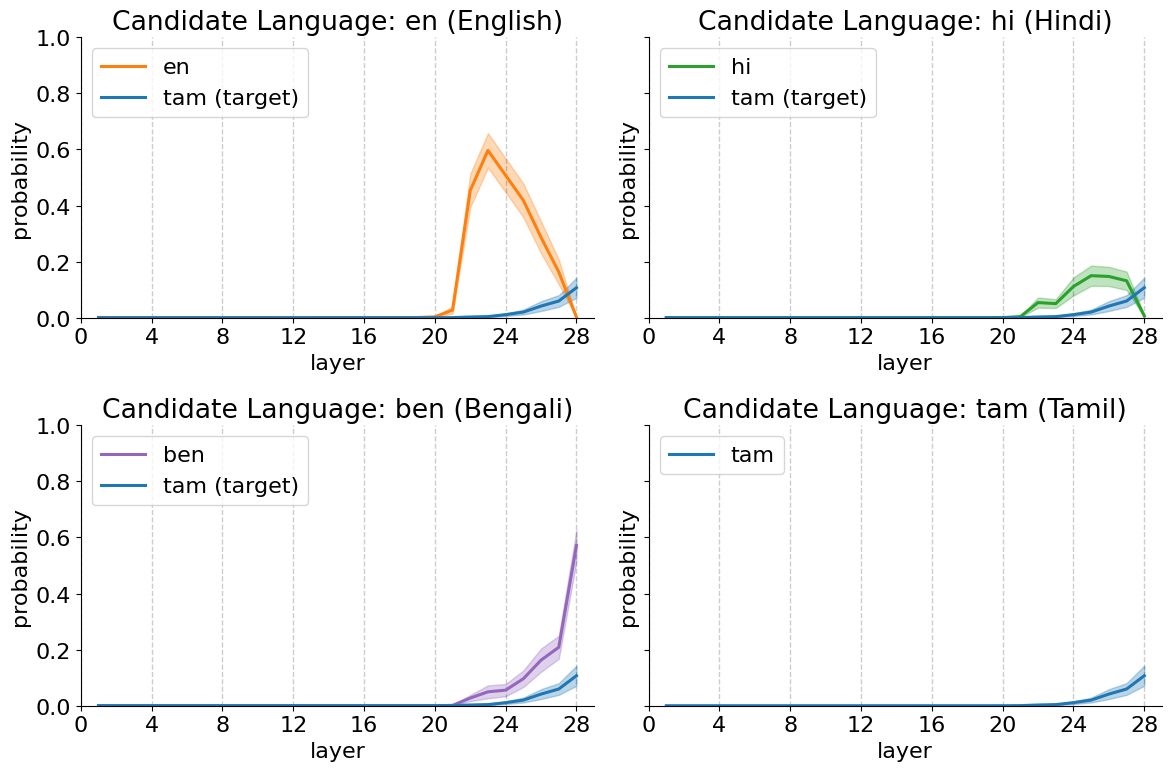

/raid/home/dgx1405/btp1-2026/llm-latent-language/utils.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


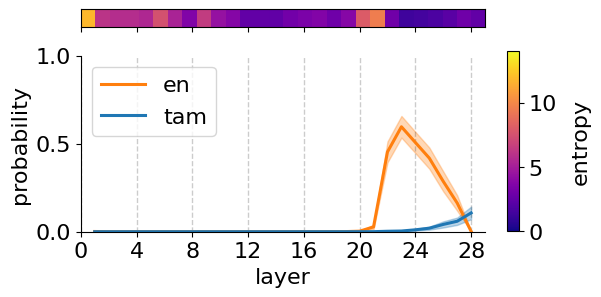

/raid/home/dgx1405/btp1-2026/llm-latent-language/utils.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


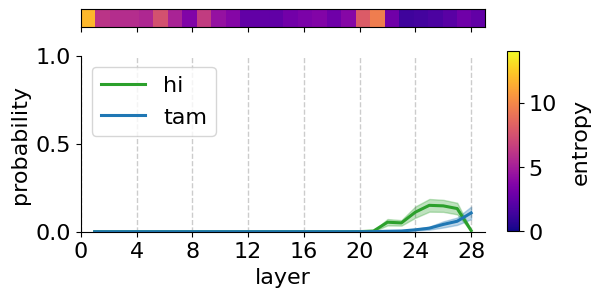

/raid/home/dgx1405/btp1-2026/llm-latent-language/utils.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


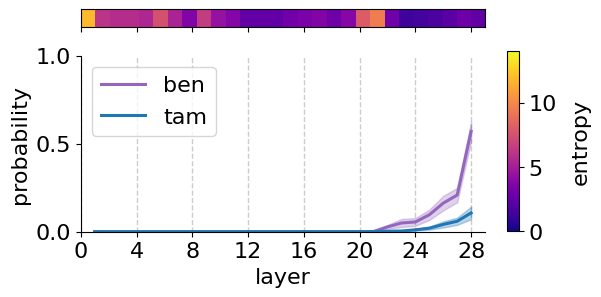

/raid/home/dgx1405/btp1-2026/llm-latent-language/utils.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


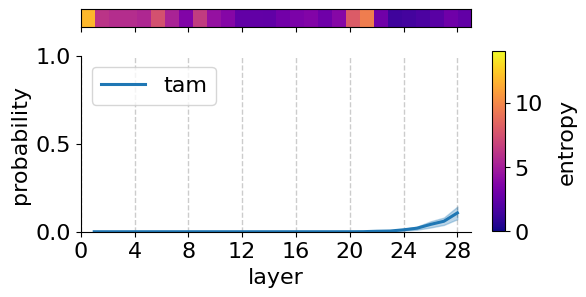

In [19]:
size2tik = {'2b': 4, '7b': 5, '13b': 5, '70b': 10}
tik_step = size2tik.get(model_size, 4)
num_layers = entropy.shape[1]

color_map = {
    'en': 'tab:orange',
    'hi': 'tab:green',
    input_lang: 'tab:purple',
    target_lang: 'tab:blue'
}

# 1. Combined 2x2 Figure with 4 Subplots
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True)
axes = axes.flatten()

for i, c in enumerate(principal_lang_candidates):
    ax = axes[i]
    c_color = color_map.get(c, 'tab:red')
    
    # Plot candidate language distribution
    plot_ci(ax, lang_probs[c], c, color=c_color, do_lines=True, tik_step=tik_step)
    
    # Overlay target language in blue if the subplot is not already target_lang
    if c != target_lang:
        plot_ci(ax, lang_probs[target_lang], f'{target_lang} (target)', color='tab:blue', do_lines=False, tik_step=tik_step)
        
    ax.set_title(f'Candidate Language: {c} ({lang2english_name.get(c, c)})')    
    ax.set_xlabel('layer')
    ax.set_ylabel('probability')
    ax.set_xlim(0, num_layers + 1)
    ax.set_ylim(0, 1)
    ax.legend(loc='upper left')

plt.tight_layout()
plt.savefig(f'{save_path}/{model_size}_{input_lang}_{target_lang}_4_candidates_grid.pdf', dpi=300, bbox_inches='tight')
plt.show()

# 2. Individual Paper-Style Plots (with Entropy Heatmap) per Candidate Language
for c in candidates:
    c_color = color_map.get(c, 'tab:orange')
    fig, ax, ax2 = plot_ci_plus_heatmap(
        lang_probs[c], 
        entropy, 
        c, 
        color=c_color, 
        tik_step=tik_step, 
        do_colorbar=True,
        nums=[.99, 0.18, 0.025, 0.6]
    )
    if c != target_lang:
        plot_ci(ax2, lang_probs[target_lang], target_lang, color='tab:blue', do_lines=False)
        
    ax2.set_xlabel('layer')
    ax2.set_ylabel('probability')
    ax2.set_xlim(0, num_layers + 1)
    ax2.set_ylim(0, 1)
    ax2.legend(loc='upper left')
    plt.savefig(f'{save_path}/{model_size}_{input_lang}_{target_lang}_probas_ent_candidate_{c}.pdf', dpi=300, bbox_inches='tight')
    plt.show()

#### Block 11: Energy Plot & Saving Latents

Plots the layer-wise energy curve and saves the extracted latent tensors.

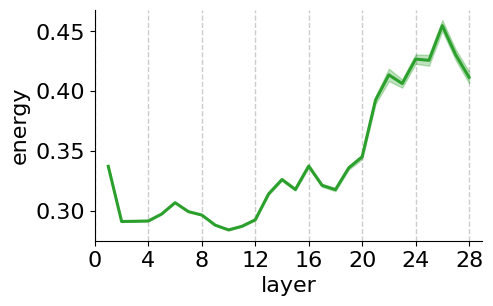

In [20]:
fig, ax2 = plt.subplots(figsize=(5, 3))
plot_ci(ax2, energy, 'energy', color='tab:green', do_lines=True, tik_step=tik_step)
ax2.set_xlabel('layer')
ax2.set_ylabel('energy')
ax2.set_xlim(0, num_layers + 1)

plt.savefig(f'{save_path}/{model_size}_{input_lang}_{target_lang}_energy.pdf', dpi=300, bbox_inches='tight')
plt.show()

torch.save(latents, f'{save_path}/{model_size}_{input_lang}_{target_lang}_latents.pt')
torch.save(lang_probs, f'{save_path}/{model_size}_{input_lang}_{target_lang}_lang_probs.pt')